=== RESUMEN EJECUTIVO POR SEDE ===
           Sede  Total_Ingresos  Margen_Promedio_Pct  Dias_Entrega_Prom
0  Barranquilla       163427.55            51.858611           4.500000
1        Bogotá       153626.38            50.415000           4.264706
2          Cali       123995.89            46.562857           5.000000
3      Medellín       111870.84            59.315455           5.590909


FileNotFoundError: [Errno 2] No such file or directory: 'outputs/reporte_ingresos_sede.png'

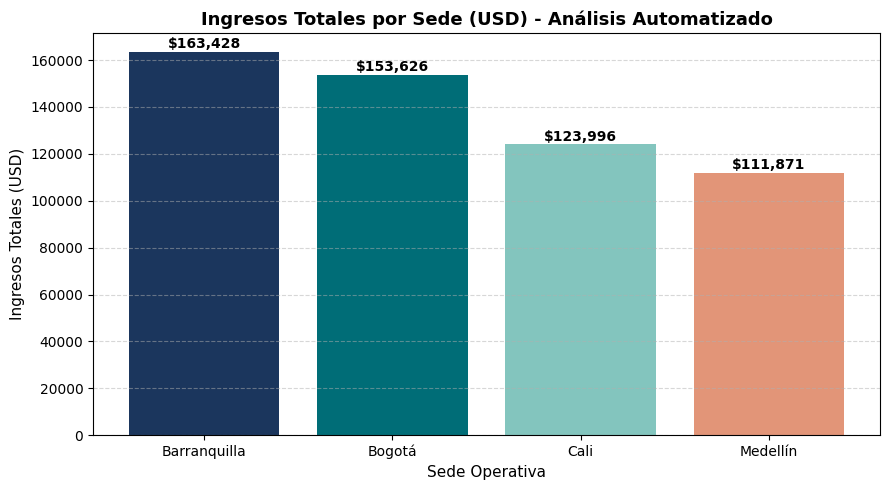

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Generación de dataset simulado de operaciones y ventas (estilo ERP/CRM)
np.random.seed(42)
n_registros = 120

data = {
    "Fecha": pd.date_range(start="2026-01-01", periods=n_registros, freq="D"),
    "Sede": np.random.choice(["Medellín", "Bogotá", "Cali", "Barranquilla"], n_registros),
    "Categoria": np.random.choice(["Corporativo B2B", "Retail B2C", "Servicios Postventa"], n_registros),
    "Ingresos_USD": np.random.normal(loc=4500, scale=1200, size=n_registros).round(2),
    "Costo_Operativo_USD": np.random.normal(loc=2100, scale=600, size=n_registros).round(2),
    "Tiempo_Entrega_Dias": np.random.randint(1, 10, size=n_registros)
}

df = pd.DataFrame(data)

# Introducir algunos valores nulos intencionales para demostrar limpieza de datos
df.loc[5:8, "Ingresos_USD"] = np.nan

# 2. Limpieza y Transformación (ETL básico)
df["Ingresos_USD"] = df["Ingresos_USD"].fillna(df["Ingresos_USD"].median())
df["Margen_Neto_USD"] = df["Ingresos_USD"] - df["Costo_Operativo_USD"]
df["Margen_Porcentaje"] = ((df["Margen_Neto_USD"] / df["Ingresos_USD"]) * 100).round(2)

# 3. Resumen Ejecutivo por Sede
resumen_sede = df.groupby("Sede").agg(
    Total_Ingresos=("Ingresos_USD", "sum"),
    Margen_Promedio_Pct=("Margen_Porcentaje", "mean"),
    Dias_Entrega_Prom=("Tiempo_Entrega_Dias", "mean")
).reset_index()

print("=== RESUMEN EJECUTIVO POR SEDE ===")
print(resumen_sede)

# 4. Visualización Gerencial y Exportación
plt.figure(figsize=(9, 5))
colores = ["#1B365D", "#006D77", "#83C5BE", "#E29578"]
barras = plt.bar(resumen_sede["Sede"], resumen_sede["Total_Ingresos"], color=colores)

plt.title("Ingresos Totales por Sede (USD) - Análisis Automatizado", fontsize=13, fontweight="bold")
plt.xlabel("Sede Operativa", fontsize=11)
plt.ylabel("Ingresos Totales (USD)", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.5)

for barra in barras:
    yval = barra.get_height()
    plt.text(barra.get_x() + barra.get_width()/2, yval + 1500, f"${yval:,.0f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig("outputs/reporte_ingresos_sede.png", dpi=300)
print("\nGráfico guardado exitosamente en outputs/reporte_ingresos_sede.png")